# AutoCause walkthrough

Follow the analysis in the order a practitioner would:

1. Inspect the raw series, timestamps, and gaps.
2. Audit assumptions before transforming the data.
3. Preprocess and inspect the recorded changes.
4. Configure discovery and examine consensus and evidence checks.
5. Read the statistics and their limitations.
6. Retain the decisions, data, and environment.

A few things to know first. The audit and preprocessing sections are separate demonstrations: the full workflow takes the raw `df` and runs those stages itself, so passing `df_pre` would preprocess twice. And an audit abstention is recorded but does not stop discovery.

Everything is written to `walkthrough_output/`, independently of the [quickstart](quickstart.ipynb). Restart the kernel if you change the code.

Evidence grades support review. They do not establish causal truth.

## Setup

Use **Python 3.13**. With both repositories cloned as siblings, install from the AutoCause root:

```bash
python -m pip install -e . -e "../causal-audit[viz]" ipykernel
python -m ipykernel install --user --name autocause --display-name "Python (autocause)"
```

Select **Python (autocause)**. The version and import path printed below tell you which code is actually running, and this example needs the companion audit package.

Your data needs numeric columns and a chronological, unique `DatetimeIndex`. Set `sampling_days` to the real observation spacing, resolve duplicate timestamps, and document how gaps were handled.

The example simulates 600 daily observations with Gaussian innovations and four known lag 1 links. Those edges exist only for scoring; discovery never sees them.

In [1]:
import json
import contextlib
import logging
from importlib.metadata import version
from pathlib import Path

# Relative output directory so the notebook is portable.
EXAMPLES_DIR = Path("examples") if Path("examples").is_dir() else Path(".")

# File-only backend: the pipeline's own figures are written to disk rather than
# embedded here. The plots below are saved and shown explicitly.
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

import numpy as np
import pandas as pd
import autocause
from causal_audit import RiskAwareGatekeeper
from autocause.core.run_workflow import run_causal_discovery_workflow

print("AutoCause distribution:", version("autocause"))
print("Causal-Audit distribution:", version("causal-audit"))

output_dir = EXAMPLES_DIR / "walkthrough_output"
output_dir.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(0)
n = 600
x = np.zeros((n, 5))
# Cross-variable lag-1 structure: X0 -> X1, X1 -> X2, X0 -> X3, X3 -> X4.
# X0 also has an autoregressive self-link, excluded from this evaluation.
for t in range(1, n):
    x[t, 0] = 0.5 * x[t - 1, 0] + rng.normal(0, 1)
    x[t, 1] = 0.6 * x[t - 1, 0] + rng.normal(0, 1)
    x[t, 2] = 0.6 * x[t - 1, 1] + rng.normal(0, 1)
    x[t, 3] = 0.5 * x[t - 1, 0] + rng.normal(0, 1)
    x[t, 4] = 0.6 * x[t - 1, 3] + rng.normal(0, 1)

cols = ["X0", "X1", "X2", "X3", "X4"]
index = pd.date_range("2020-01-01", periods=n, freq="D")
df = pd.DataFrame(x, columns=cols, index=index)

true_edges = {("X0", "X1"), ("X1", "X2"), ("X0", "X3"), ("X3", "X4")}
print(f"Data: {df.shape[0]} rows, {df.shape[1]} variables")
print(f"Cross-variable ground-truth edges: {sorted(true_edges)}")


def show_fig(fig, name):
    """Save a figure to the output directory and show it inline."""
    path = output_dir / name
    fig.savefig(path, dpi=120, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(path)))

AutoCause distribution: 0.2.0
Causal-Audit distribution: 0.3.1
Data: 600 rows, 5 variables
Cross-variable ground-truth edges: [('X0', 'X1'), ('X0', 'X3'), ('X1', 'X2'), ('X3', 'X4')]


In [2]:
@contextlib.contextmanager
def notebook_log(path):
    """Optional notebook utility: retain verbose output without filling the page."""
    root_logger = logging.getLogger()
    previous_handlers = root_logger.handlers[:]
    previous_disable = root_logger.manager.disable
    try:
        with path.open("w") as log, contextlib.redirect_stdout(log), contextlib.redirect_stderr(log):
            root_logger.handlers = [logging.StreamHandler(log)]
            logging.disable(logging.NOTSET)
            yield
    finally:
        root_logger.handlers = previous_handlers
        logging.disable(previous_disable)


## 1. Inspect the raw data

Plot the series before trusting any output. You are checking for scale, drift, and gaps, plus the things that change how the data reads: trend, outliers, variance shifts, or a seasonal cycle shared by every variable.

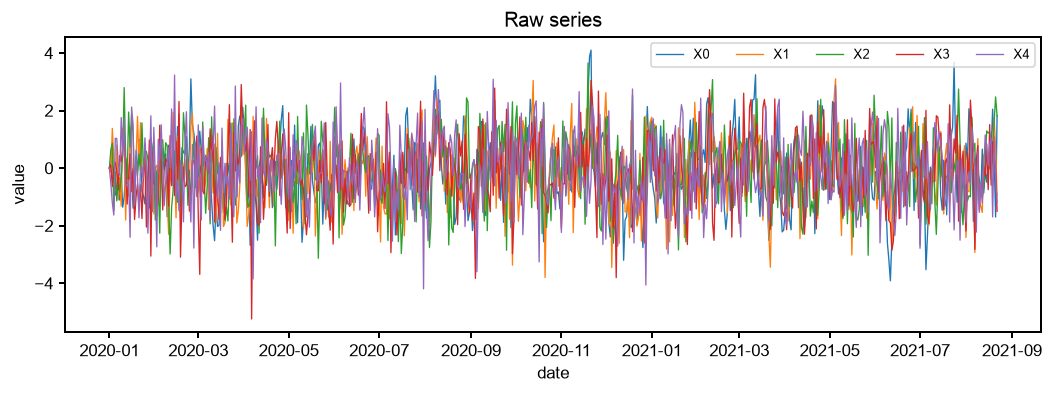

In [3]:
fig, ax = plt.subplots(figsize=(10.5, 3.2))
for c in cols:
    ax.plot(df.index, df[c], lw=0.8, label=c)
ax.set_title("Raw series")
ax.set_xlabel("date")
ax.set_ylabel("value")
ax.legend(ncol=5, fontsize=8, loc="upper right")
show_fig(fig, "fig_raw_series.png")

## 2. Audit the raw data

Causal-Audit returns diagnostics, risk scores, and either a recommendation or an abstention. Read the rationale now: preprocessing comes next and changes the evidence underneath it.

The implementation reports six score families, while the submitted paper evaluates four calibrated dimensions. Treat the bounds as approximate, not as posterior intervals.

In [4]:
import contextlib
import logging

audit_dir = output_dir / "causal_audit_standalone"
audit_log = output_dir / "audit_run.log"

risks = {}
policy = {}
try:
    from causal_audit import RiskAwareGatekeeper

    with (
        open(audit_log, "w") as _log,
        contextlib.redirect_stdout(_log),
        contextlib.redirect_stderr(_log),
    ):
        gatekeeper = RiskAwareGatekeeper(random_seed=42)
        audit = gatekeeper.analyze(data=df, output_dir=str(audit_dir))
    pol = audit["policy"]
    print(f"Decision:    {pol.decision.upper()}")
    if pol.decision == "recommend":
        print(f"Recommended: {pol.recommended_method}")
        if pol.confidence is not None:
            print(f"Confidence (policy score): {pol.confidence:.0%}")
        print("Proposed configuration:", json.dumps(pol.method_config, indent=2))
    print("Rationale:", audit["scorecard"].rationale)
    risks = audit["risk_profile"].risks
    print("\nAssumption risks (score [approximate bounds], low values = weaker diagnostic signals):")
    for name, r in risks.items():
        label = {"ConfoundingRisk": "Confounding proxy", "SeasonalityRisk": "Spectral/trend proxy"}.get(name, name.replace("Risk", ""))
        print(f"  {label:<16} {r['mean']:.2f}  [{r['lower_95']:.2f}, {r['upper_95']:.2f}]")
except ImportError:
    print("Audit stage skipped. Install the companion package to enable it:")
    print("  pip install -e ../causal-audit  (from an AutoCause checkout)")


Decision:    RECOMMEND
Recommended: PCMCI+
Confidence (policy score): 85%
Proposed configuration: {
  "pcmci": {
    "enabled": true,
    "test_method": "parcorr",
    "allow_contemporaneous": true
  },
  "granger": {
    "enabled": true,
    "note": "fast linear baseline"
  },
  "method": "PCMCI+",
  "tau_max": 12,
  "alpha": 0.05,
  "fdr_method": "fdr_bh"
}
Rationale: Low structural risk profile: PCMCI+(ParCorr) is the linear default. The audit does not establish the non-Gaussian innovations required by VARLiNGAM. Check stationarity, causal sufficiency and the chosen lag horizon separately. IrregularityRisk=0.18; gaps require explicit handling before discovery.

Assumption risks (score [approximate bounds], low values = weaker diagnostic signals):
  Nonstationarity  0.11  [0.06, 0.16]
  Irregularity     0.18  [0.12, 0.24]
  Persistence      0.03  [0.01, 0.05]
  Confounding proxy 0.06  [0.03, 0.09]
  Nonlinearity     0.19  [0.10, 0.28]
  Spectral/trend proxy 0.13  [0.06, 0.20]


The summary above shows the data, the scores, the ACF, the predictive diagnostic, and the policy decision. Two readings matter: random forest gain measures prediction rather than causation, and policy confidence says nothing about graph accuracy.

Assumptions also limit the result. Gaussian innovations are what make ParCorr a good fit here and what rule out VARLiNGAM; PCMCI+ additionally assumes stationarity, causal sufficiency, and the Markov and faithfulness conditions. See [Tigramite's requirements](https://github.com/jakobrunge/tigramite#overview) and [VARLiNGAM's assumptions](https://lingam.readthedocs.io/en/latest/tutorial/var.html).

Agreement between methods is also weaker evidence than it looks. Conditional Granger and PCMCI+ use multivariate information, while pairwise transfer entropy and the bivariate checks can pick up mediated or confounded associations. Several methods finding the same link in the same data is not independent replication.

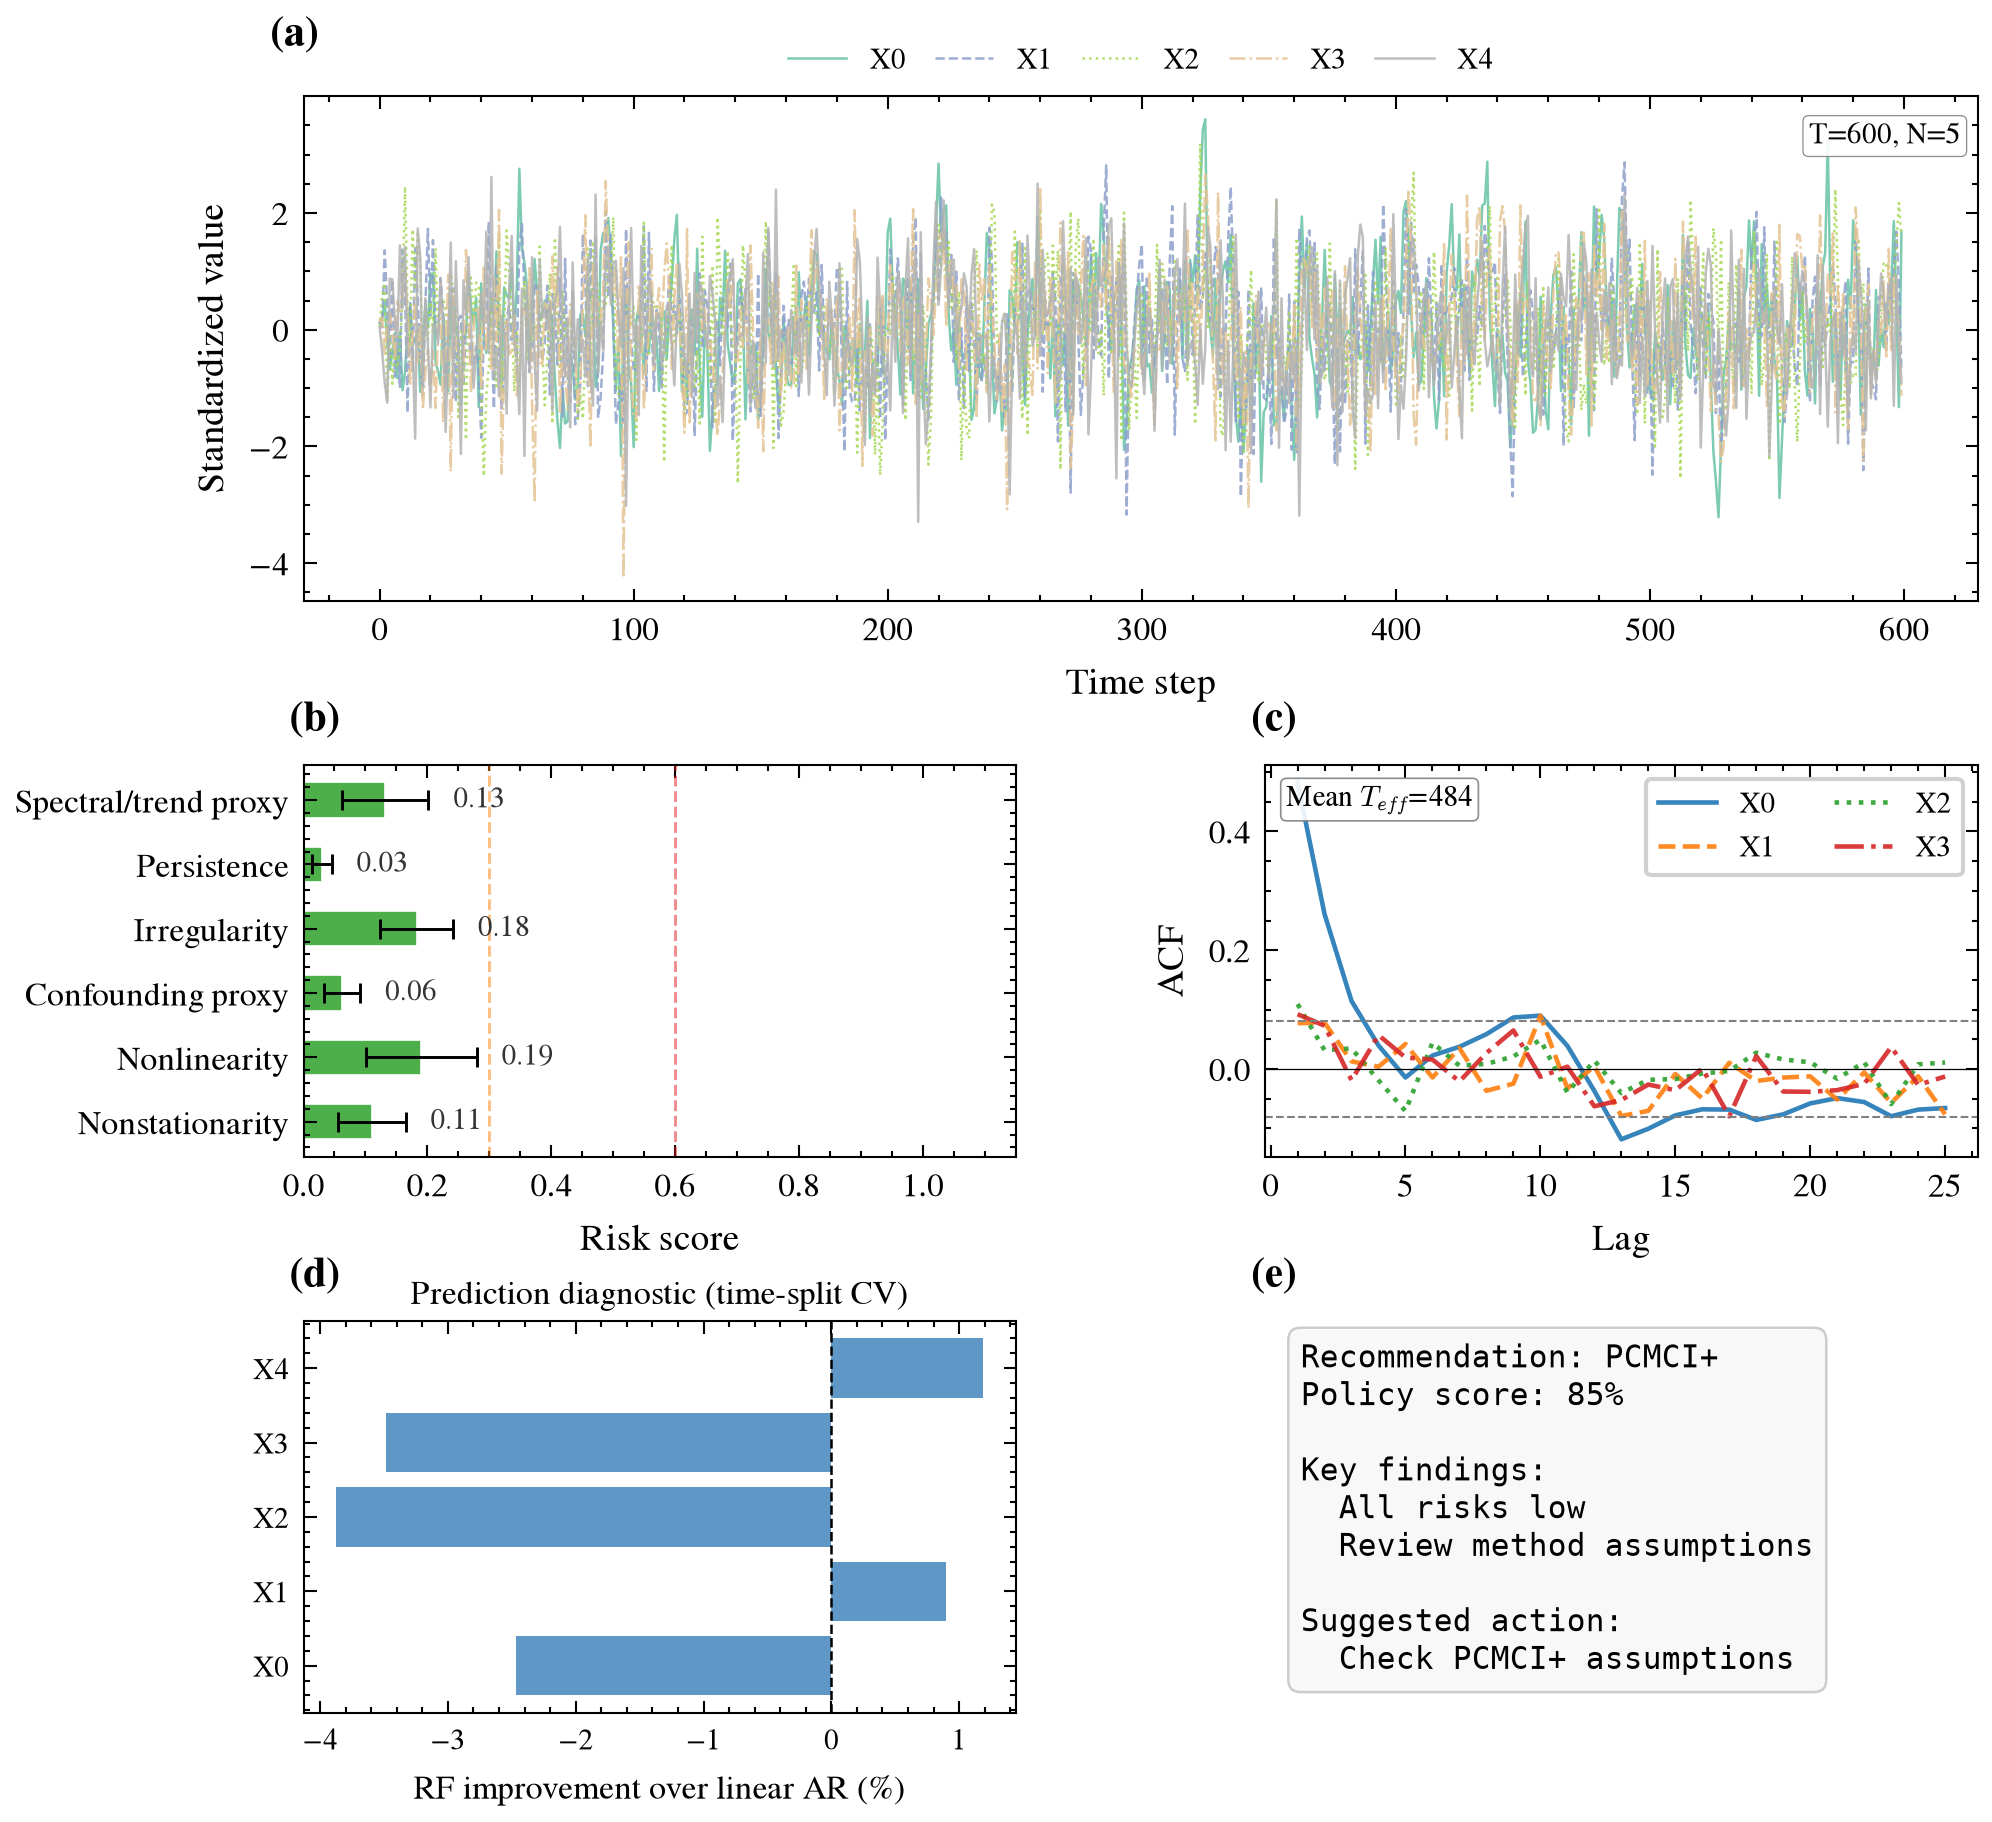

In [5]:
summary_png = audit_dir / "figures" / "prediscovery_summary.png"
if summary_png.exists():
    display(Image(filename=str(summary_png)))
else:
    print("Audit figure not available (causal-audit not installed).")

## 3. Preprocess and inspect changes

The report records gap treatment, outliers, stationarity tests, and normalization. Differencing can address a unit root, but it does not guarantee stationarity, and it shifts the interpretation from levels to changes.

This demo runs both ADF and KPSS, whereas the preprocessor inside the workflow uses ADF only, so the two reports can disagree. Keep the raw `df` for the complete run.

In [6]:
from autocause.core.preprocessing import TimeSeriesPreprocessor

with notebook_log(output_dir / "preprocess_run.log"):
    pre = TimeSeriesPreprocessor(stationarity_test="both", normalize=True)
    df_pre, report = pre.preprocess(df, verbose=True)

print(f"Shape: {report.original_shape} -> {report.final_shape}")
print("\nStationarity diagnostic per variable (ADF + KPSS criterion):")
for col, st in report.stationarity_tests.items():
    verdict = "stationary" if st.get("both_agree") else "flagged / inconclusive"
    adf = st.get("adf_pvalue", float("nan"))
    kpss_p = st.get("kpss_pvalue", float("nan"))
    print(f"  {col}: {verdict:<15} (ADF p={adf:.2g}, KPSS p={kpss_p:.2g})")

if report.quality_flags:
    print("\nQuality flags:")
    for f in report.quality_flags:
        print(f"  {f}")
else:
    print("\nNo quality flags: the series needed no differencing.")


Shape: (600, 5) -> (600, 5)

Stationarity diagnostic per variable (ADF + KPSS criterion):
  X0: stationary      (ADF p=1e-26, KPSS p=0.1)
  X1: stationary      (ADF p=3.2e-28, KPSS p=0.1)
  X2: stationary      (ADF p=0, KPSS p=0.1)
  X3: stationary      (ADF p=3.4e-28, KPSS p=0.1)
  X4: stationary      (ADF p=0, KPSS p=0.1)

No quality flags: the series needed no differencing.


Raw versus preprocessed for one variable. Normalisation recentres and rescales the series; nothing needed differencing here, so the shape is preserved.

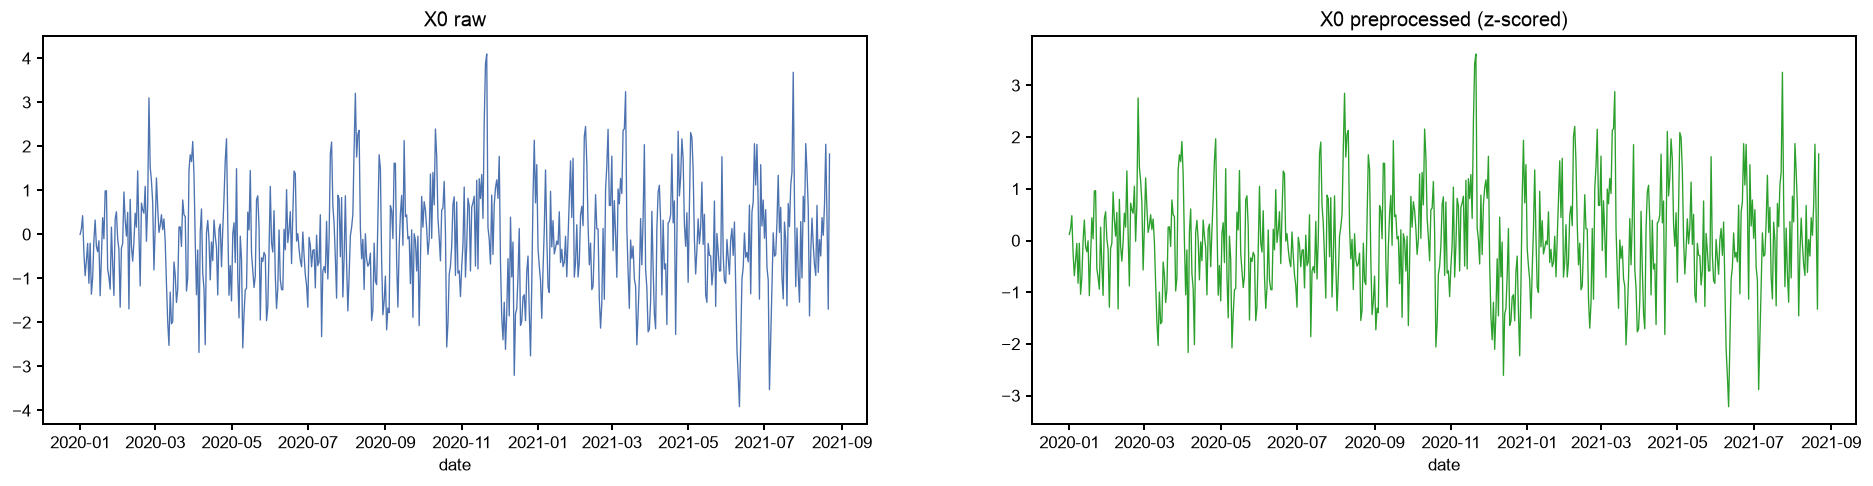

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(19.5, 4.2), sharex=True)
ax1.plot(df.index, df["X0"], lw=0.8, color="#4C72B0")
ax1.set_title("X0 raw")
ax2.plot(df_pre.index, df_pre["X0"], lw=0.8, color="#2CA02C")
ax2.set_title("X0 preprocessed (z-scored)")
for a in (ax1, ax2):
    a.set_xlabel("date")
show_fig(fig, "fig_preprocess_x0.png")

## 4. Configure and run discovery

We run on the raw `df` and write to a separate output folder, enabling Granger, PCMCI+ with ParCorr, and transfer entropy. Correlation and the random forest come along as noncausal comparisons and do not vote; VARLiNGAM stays off for Gaussian innovations.

| Setting | Choice here |
| --- | --- |
| `tau_max=None` | Estimate the lag horizon; an integer overrides it. |
| `alpha=0.05` | Check each method's correction family. |
| `test_method="parcorr"` | Explicit CI test for linear Gaussian data. |
| `apply_audit_recommendation=False` | Keep explicit choices, and still record the audit's advice. |
| `true_edges` | For evaluation only; discovery does not use them. |

The complete call performs its own audit and preprocessing. Logs go to `pipeline_run.log`, and stale outputs in this folder can be cleaned before a rerun.

In [8]:
from autocause.core.run_workflow import run_causal_discovery_workflow

run_log = output_dir / "pipeline_run.log"

with notebook_log(run_log):
    result = run_causal_discovery_workflow(
        data_df=df,
        output_dir=output_dir,
        tau_max=None,  # estimate the maximum lag from the data
        alpha=0.05,
        sampling_days=1,
        true_edges=true_edges,
        undirected_eval=True,
        enable_consensus=True,
        enable_causal_audit=True,
        apply_audit_recommendation=False,  # explicit choices explained above
        method_config={
            "granger": {"enabled": True},
            "pcmci": {"enabled": True, "test_method": "parcorr"},
            "transfer_entropy": {"enabled": True},
            "correlation": {"enabled": True},
            "predictive_baseline": {"enabled": True},
            "varlingam": {"enabled": False},
            "lpcmci": {"enabled": False},
        },
    )
print(f"Workflow finished: success={result['success']}")

# Report the automated analysis decisions the pipeline made and recorded.
tau_json = output_dir / "tau_max_estimation.json"
if tau_json.exists():
    tau = json.loads(tau_json.read_text())
    print(
        f"Estimated tau_max: {tau.get('tau_max')} step(s) "
        f"(binding constraint: {tau.get('binding_constraint')}, "
        f"method: {tau.get('method')})"
    )
adeq_json = output_dir / "sample_size_adequacy.json"
if adeq_json.exists():
    adeq = json.loads(adeq_json.read_text())
    print(
        f"Sample size: {adeq.get('n_observations')} obs, "
        f"{adeq.get('n_variables')} vars -> adequate: {adeq.get('overall_adequate')}"
    )

Workflow finished: success=True
Estimated tau_max: 2 step(s) (binding constraint: acf, method: scientific_hybrid)
Sample size: 600 obs, 5 vars -> adequate: True


### Read the evidence grades

Only significant detections from causal methods vote, and lagged links are scored separately from contemporaneous ones.

1. **Tier 1**: at least two methods, both surrogate checks, and stable coefficients across temporal blocks.
2. **Tier 2**: at least two methods plus either a surrogate check or out of sample support.
3. **Tier 3**: everything else, including strongly significant Granger only candidates.

Two limits here. Block permutation and IAAFT require both the original and empirical p values below alpha; the table shows empirical values and `checks` counts passes, so with 200 surrogates the smallest possible value is 1/201, not zero ([finite permutation correction](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html)).

These null models only test bivariate lagged association. They are neither independent validation nor a control for selecting links, and `stable` reports a coefficient stability heuristic rather than formal ICP.

In [9]:
tiers_csv = output_dir / "consensus" / "5-tiers" / "consensus_with_tiers.csv"
tiers = None
if tiers_csv.exists():
    tiers = pd.read_csv(tiers_csv)
    columns = {
        "source": "source", "target": "target", "lag_steps": "lag",
        "vote_count": "votes", "falsification_passed": "checks",
        "block_perm_empirical_pvalue": "block p", "iaaft_empirical_pvalue": "IAAFT p",
        "icp_stable": "stable", "tier": "tier",
    }
    summary = tiers.sort_values("tier")[list(columns)].rename(columns=columns)
    print(summary.to_string(index=False, float_format=lambda x: f"{x:.3g}"))
    counts = tiers["tier"].value_counts().sort_index()
    print("\nLinks per tier:", {f"Tier {int(t)}": int(c) for t, c in counts.items()})

source target  lag  votes  checks  block p  IAAFT p  stable  tier
    X3     X4    1      3       2  0.00498  0.00498    True     1
    X1     X2    1      3       2  0.00498  0.00498    True     1
    X0     X1    1      3       2  0.00498  0.00498    True     1
    X0     X3    1      3       2  0.00498  0.00498    True     1
    X2     X3    2      1       0   0.0398   0.0398   False     3

Links per tier: {'Tier 1': 4, 'Tier 3': 1}


**Reading the graph.** Green links match the simulated direction, gray links are spurious, and red links were missed. Labels give the lag and the tier.

These counts also require the correct lag; the skeleton metrics below ignore both direction and lag.

Directed + exact-lag recovery: TP=4, FP=1, FN=0


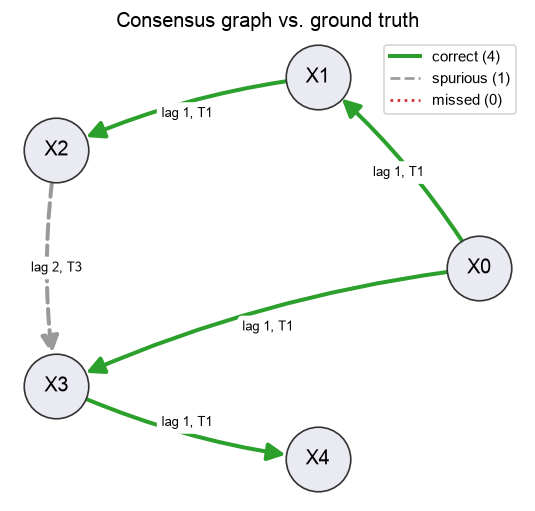

In [10]:
import networkx as nx

if tiers is not None and len(tiers) > 0:
    recovered = {(r.source, r.target) for r in tiers.itertuples()}
    tp = recovered & true_edges
    fp = recovered - true_edges
    fn = true_edges - recovered

    truth_lagged = {(s, t, 1) for s, t in true_edges}
    recovered_lagged = {(r.source, r.target, int(r.lag_steps)) for r in tiers.itertuples()}
    print(f"Directed + exact-lag recovery: TP={len(recovered_lagged & truth_lagged)}, "
          f"FP={len(recovered_lagged - truth_lagged)}, FN={len(truth_lagged - recovered_lagged)}")

    g = nx.DiGraph()
    g.add_nodes_from(cols)
    for e in tp | fp | fn:
        g.add_edge(*e)
    pos = nx.circular_layout(g)

    fig, ax = plt.subplots(figsize=(5.5, 5.0))
    nx.draw_networkx_nodes(g, pos, node_color="#EAEAF2", edgecolors="#333333",
                           node_size=1500, ax=ax)
    nx.draw_networkx_labels(g, pos, font_size=12, ax=ax)
    nx.draw_networkx_edges(g, pos, edgelist=list(tp), edge_color="#2CA02C", width=2.4,
                           arrowsize=22, node_size=1500, connectionstyle="arc3,rad=0.08", ax=ax)
    nx.draw_networkx_edges(g, pos, edgelist=list(fp), edge_color="#999999", width=2.4,
                           style="dashed", arrowsize=22, node_size=1500, connectionstyle="arc3,rad=0.08", ax=ax)
    nx.draw_networkx_edges(g, pos, edgelist=list(fn), edge_color="#D62728", width=2.4,
                           style="dotted", arrowsize=22, node_size=1500, connectionstyle="arc3,rad=0.08", ax=ax)
    edge_labels = {(r.source, r.target): f"lag {int(r.lag_steps)}, T{int(r.tier)}"
                   for r in tiers.itertuples()}
    nx.draw_networkx_edge_labels(g, pos, edge_labels=edge_labels, rotate=False,
                                font_size=8, ax=ax)
    handles = [
        plt.Line2D([0], [0], color="#2CA02C", lw=2.4, label=f"correct ({len(tp)})"),
        plt.Line2D([0], [0], color="#999999", lw=1.6, ls="--", label=f"spurious ({len(fp)})"),
        plt.Line2D([0], [0], color="#D62728", lw=1.6, ls=":", label=f"missed ({len(fn)})"),
    ]
    ax.legend(handles=handles, loc="upper right", fontsize=9, frameon=True)
    ax.set_title("Consensus graph vs. ground truth")
    ax.axis("off")
    show_fig(fig, "fig_consensus_graph.png")

## 5. Read the statistics

These scores compare variable pair skeletons against the known graph and ignore direction and lag. Chance precision is `m_true / m_max`, so compare it with precision rather than F1. Real data rarely comes with a known graph, so this kind of evaluation is usually unavailable.

Transfer entropy has its own problems: finite Monte Carlo p values with BH correction across lags within each pair rather than across pairs, and a source shuffle null that acts as an association diagnostic. In finite samples it produces both false positives and missed links.

Full results are in `graph_recovery_metrics.csv` and `graph_recovery_metrics_extras.json`.

In [11]:
enabled_methods = {
    "granger", "pcmci", "transfer_entropy", "correlation", "predictive_baseline",
}
# A failed estimator must not be scored as if it successfully found no links.
valid_methods = enabled_methods.copy()
te_raw_csv = output_dir / "method" / "transfer_entropy" / "1-raw" / "results_transfer_entropy.csv"
if "transfer_entropy" in valid_methods:
    te_raw = pd.read_csv(te_raw_csv) if te_raw_csv.exists() else pd.DataFrame()
    te_p = pd.to_numeric(te_raw.get("p_value", pd.Series(dtype=float)), errors="coerce")
    if not np.isfinite(te_p).any():
        valid_methods.remove("transfer_entropy")
        print("Transfer entropy: no valid test results; excluded from performance comparisons.")
        print("Inspect pipeline_run.log or experiment.log for the execution error.\n")

metrics_df = None
metrics_csv = output_dir / "graph_recovery_metrics.csv"
if metrics_csv.exists():
    metrics_df = pd.read_csv(metrics_csv)
    metrics_df = metrics_df[metrics_df["method"].isin(valid_methods)]
    cols_show = [c for c in ["method", "precision", "recall", "f1"] if c in metrics_df.columns]
    print(metrics_df[cols_show].to_string(index=False, float_format=lambda x: f"{x:.3f}"))

chance_precision = None
extras_json = output_dir / "graph_recovery_metrics_extras.json"
if extras_json.exists():
    extras = json.loads(extras_json.read_text())
    chance = extras.get("chance_baseline", {})
    if chance:
        chance_precision = chance.get("expected_precision")
        print(
            f"\nChance precision (random guess): {chance_precision:.3f} "
            f"(m_true={chance.get('m_true')}, m_max={chance.get('m_max')})"
        )

             method  precision  recall    f1
            granger      0.800   1.000 0.889
   transfer_entropy      0.667   1.000 0.800
              pcmci      0.800   1.000 0.889
predictive_baseline      0.400   1.000 0.571
        correlation      0.400   1.000 0.571

Chance precision (random guess): 0.400 (m_true=4, m_max=10)


Blue bars are causal methods, gray bars are the association and prediction baselines, and the red line is chance precision rather than a significance threshold.

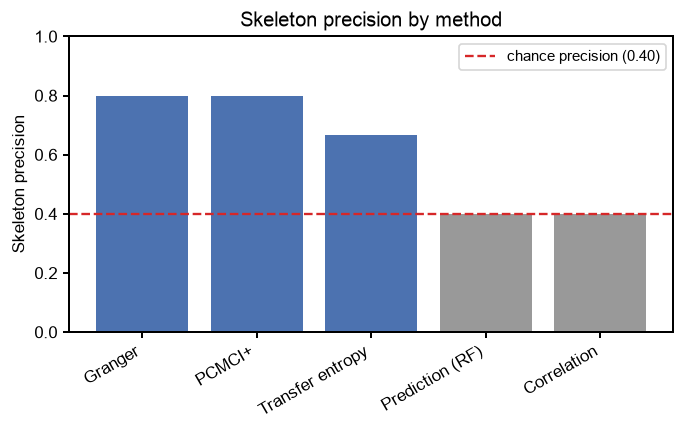

In [12]:
if metrics_df is not None and len(metrics_df) > 0:
    md = metrics_df.sort_values("precision", ascending=False)
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    labels = {"granger": "Granger", "pcmci": "PCMCI+", "transfer_entropy": "Transfer entropy",
              "predictive_baseline": "Prediction (RF)", "correlation": "Correlation"}
    colors = ["#999999" if m in {"correlation", "predictive_baseline"} else "#4C72B0"
              for m in md["method"]]
    ax.bar(md["method"].map(labels), md["precision"], color=colors)
    if chance_precision is not None:
        ax.axhline(chance_precision, color="#D62728", ls="--", lw=1.4,
                   label=f"chance precision ({chance_precision:.2f})")
        ax.legend(fontsize=9)
    ax.set_ylim(0, 1)
    ax.set_ylabel("Skeleton precision")
    ax.set_title("Skeleton precision by method")
    ax.set_xticks(range(len(md)))
    ax.set_xticklabels(md["method"].map(labels), rotation=30, ha="right")
    show_fig(fig, "fig_method_precision.png")

## 6. Retain the evidence

`preprocessing_report.json`, `tau_max_estimation.json`, and `sample_size_adequacy.json` record the data changes and the analysis choices. The audit scorecard, the method CSVs, and the consensus `tier_report.txt` record link support.

The cell below prints each record as a path relative to this notebook.

Keep the original data, the exact configuration, the package versions, and the environment. Before interpreting any candidate driver, check that it survives reasonable changes in preprocessing, lag horizon, and method choice.

In [13]:
records = sorted(output_dir.glob("*.json"))
print("Decision and diagnostic records (relative to this notebook):")
for path in records:
    print("  ", path.relative_to(EXAMPLES_DIR))

Decision and diagnostic records (relative to this notebook):
   walkthrough_output/distribution_tests.json
   walkthrough_output/experiment_log.json
   walkthrough_output/graph_recovery_metrics_extras.json
   walkthrough_output/power_analysis.json
   walkthrough_output/preprocessing_report.json
   walkthrough_output/sample_size_adequacy.json
   walkthrough_output/tau_max_estimation.json
   walkthrough_output/temporal_validation.json
